# 05 · Tree ensembles — Domestic Flight Price (Regression)

**Why this notebook exists:** on 11 Oct the TA ruled that models built on concepts taught before the deadline are allowed, as long as we can explain how they work in the viva. Decision trees were taught, so **Random Forest and XGBoost are allowed**. SVM and neural networks are not.

**Starting point:** Phase 4's best, Ridge on polynomial + flight×class features: **CV R² 0.9262**, public 0.9492.

### The one idea behind this whole notebook

Phase 3 showed a single decision tree has two failure modes, and we saw both on our own data:

| | Single tree | Fix | Method |
|---|---|---|---|
| Too deep | memorises its rows: train 0.999, CV 0.86 (**high variance**) | grow many deep trees on different data and **average** them | **Random Forest** (bagging) |
| Too shallow | misses structure: depth 2 → 0.80 (**high bias**) | add shallow trees **one after another**, each correcting the previous errors | **Gradient boosting** (XGBoost) |

Both are "ensembles": many weak or unstable trees combined into one strong model. They attack the two halves of the bias–variance trade-off from opposite ends.

| Model | Question it answers |
|---|---|
| 12 Random Forest | Does averaging many deep trees fix the single tree's variance? |
| 13 XGBoost | Does adding small trees step by step beat Ridge? |
| 14 Averaging Ridge + RF + XGBoost | Do a linear model and tree models make *different* mistakes that cancel out? |

**What this cell does:** Standard opening: auto-reload, make `src/` importable, import `config`.

**Why:** Same as every notebook.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

**What this cell does:** Imports libraries and project modules, loads the cleaned data, silences the expected unseen-category warning.

**Why:** Same setup as Phases 3–4, plus `RandomForestRegressor`, `XGBRegressor` and `VotingRegressor` (which averages models).

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

from src import evaluate
from src.regression import preprocess as pp
from src.regression.models import FloorRegressor

warnings.filterwarnings("ignore", message="Found unknown categories")
TASK = "regression"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

X, y, X_test, test_ids, sample_sub = pp.load_clean()
RAW = list(X.columns)
print("X", X.shape, "| X_test", X_test.shape)

X (15167, 10) | X_test (3898, 10)


**What this cell does:** Defines `run()` (same as before) and rebuilds the Phase 4 Ridge model so we can combine it with the trees later.

**Why:** The averaging step (Model 14) needs the exact Phase 4 model, unchanged.

In [3]:
def run(name, model, params=None, notes=""):
    folds = evaluate.cross_validate(model, X, y, TASK, name, params=params, notes=notes)
    print(f"{name:28s} CV R² {folds.r2.mean():.4f} ± {folds.r2.std():.4f} | train R² {folds.train_r2.mean():.4f}"
          f" | RMSE ₹{folds.rmse.mean():,.0f}")
    return folds

def ridge_flight(alpha=3):
    features = ColumnTransformer([
        ("poly", make_pipeline(pp.make_preprocessor(), PolynomialFeatures(2, include_bias=False)), RAW),
        ("flight", OneHotEncoder(handle_unknown="ignore"), ["flight_key"]),
    ])
    return FloorRegressor(make_pipeline(FunctionTransformer(pp.add_flight_key), features, Ridge(alpha=alpha)))

## Features for trees

Trees need different preprocessing from linear models (`TreeEncoder` in `src/regression/preprocess.py`):

- **No scaling.** A tree only ever asks "is `duration` ≤ 9.5?". Multiplying a column by 100 just moves the threshold to 950; the split, and so the model, is identical. (Ridge is the opposite: its penalty acts on coefficient size, which depends on scale.)
- **Integer codes instead of one-hot.** Each category gets a number (e.g. airline Oceanic = 4). For a *linear* model this would be wrong: it would treat airline 4 as "twice" airline 2. A tree never multiplies by the code; it only splits on it ("code ≤ 3.5?"), and two or three splits can isolate any single category. It also keeps the flight code to **1 column instead of ~1,500**.
- **Same duration imputer** as before, re-fitted inside each fold, so the comparison with Ridge stays fair. The flight × class key from Phase 4 is included.
- **Viva trap:** "integer-coding a category imposes a fake order" is true, but it only matters for models that do arithmetic on the value (linear, distance-based). Trees are order-tolerant: a bad order just costs a few extra splits.

**What this cell does:** Shows the first rows of the tree feature matrix.

**Why:** Shows what the trees actually see: 11 numeric columns, no one-hot.

In [4]:
pp.TreeEncoder().fit(X).transform(X).head()

,airline,flight,flight_key,source_city,destination_city,departure_time,arrival_time,flight_class,stops,duration,days_left
0,15.0,850.0,1287.0,3.0,5.0,2.0,5.0,1.0,0,2.92,18
1,8.0,84.0,102.0,2.0,5.0,5.0,5.0,1.0,0,1.33,38
2,15.0,677.0,969.0,4.0,5.0,2.0,5.0,0.0,0,2.08,13
3,8.0,421.0,579.0,4.0,3.0,0.0,2.0,1.0,0,2.25,5
4,8.0,55.0,73.0,1.0,5.0,2.0,5.0,1.0,1,4.83,21


## Model 12 — Random Forest (bagging)

**The problem it solves.** A fully grown tree fits its training rows almost perfectly (train R² 0.999) but changes a lot if the training rows change slightly. That instability is **variance**: its errors on new rows are large, but they're *random*: one tree overshoots a flight, another tree trained on slightly different rows undershoots it.

**The fix: average many such trees.** Random errors cancel when averaged, while the real pattern (which every tree finds) stays. How to get "many different trees" from one dataset:

1. **Bootstrap sample (bagging = bootstrap aggregating):** each tree trains on 15,167 rows drawn *with replacement* from the training set. That's about 63% unique rows, some repeated, so every tree sees a slightly different dataset.
2. **Random feature subset at each split (`max_features`):** at every split a tree may only choose from a random fraction of the columns. Without this, all trees would pick the same strong column (class, then duration) at the top and end up nearly identical, and averaging identical trees gains nothing.
3. **Predict:** average the predictions of all trees.

**Why the feature subset matters (the one formula worth knowing):** for *n* trees each with variance σ² and pairwise correlation ρ,

  variance of the average = ρσ² + (1 − ρ)σ²/n

More trees shrink the second term towards 0, but the first term ρσ² stays. **Only making trees less correlated (smaller ρ) reduces it**, and that's what `max_features` does. With `max_features = 1.0` (all columns at every split) the forest becomes plain *bagging*.

**What it does not fix:** bias. Each tree is deep and unbiased-ish; averaging doesn't make the model able to represent something no tree can.

Knobs we tune: `max_features` (decorrelation) and `min_samples_leaf` (how deep each tree grows). The number of trees is not a complexity knob: more trees never overfit, they only cost time.

**What this cell does:** Shows the variance-reduction effect directly: CV R² of a forest with 1, 5, 20, 100 and 300 trees (max_features 0.5, min_samples_leaf 2), not logged.

**Why:** Makes the averaging argument concrete on our data. One tree in this setup is just a (bootstrapped) single deep tree; the curve shows how much of its error was variance that averaging removes.

In [5]:
def forest(n_estimators=300, max_features=0.5, min_samples_leaf=2):
    return make_pipeline(pp.TreeEncoder(), RandomForestRegressor(n_estimators=n_estimators, max_features=max_features,
                                                                 min_samples_leaf=min_samples_leaf,
                                                                 n_jobs=-1, random_state=config.SEED))

n_trees = pd.DataFrame([{"trees": n, **evaluate.cross_validate(forest(n_estimators=n), X, y, TASK, "", log=False)
                          [["r2", "train_r2"]].mean().to_dict()} for n in [1, 5, 20, 100, 300]]).set_index("trees")
display(n_trees.round(4))

,r2,train_r2
trees,,
1,0.8807,0.9381
5,0.9141,0.9639
20,0.9242,0.9696
100,0.9267,0.9715
300,0.9270,0.9717


**What this cell does:** Tries 12 combinations of max_features ∈ {0.33, 0.5, 1.0} and min_samples_leaf ∈ {1, 2, 3, 5} (300 trees), logs the best.

**Why:** Finds how much decorrelation and how much tree depth work best. `max_features = 1.0` rows are plain bagging, so the table also shows what the random feature subset adds.

In [6]:
rf_grid = [{"max_features": f, "min_samples_leaf": l} for f in [0.33, 0.5, 1.0] for l in [1, 2, 3, 5]]
rf_table, rf_best = evaluate.grid_search(forest, rf_grid, X, y, TASK, "12_random_forest",
                                         notes="300 trees on TreeEncoder features")
display(rf_table.round(4))
print("best:", rf_best)

,max_features,min_samples_leaf,r2_mean,r2_std,train_r2
0,0.50,3,0.9278,0.0025,0.9628
1,0.33,3,0.9271,0.0023,0.9586
2,0.50,2,0.9270,0.0033,0.9717
3,0.50,5,0.9269,0.0025,0.9528
4,0.33,2,0.9268,0.0025,0.9680
5,0.33,5,0.9253,0.0024,0.9486
6,1.00,3,0.9249,0.0045,0.9675
7,1.00,2,0.9246,0.0048,0.9766
8,1.00,5,0.9238,0.0042,0.9562
9,0.50,1,0.9225,0.0030,0.9900


best: {'max_features': 0.5, 'min_samples_leaf': 3}


**What this cell does:** Fits the best forest on all rows and shows its feature importances.

**Why:** Compares what the forest relies on with the single tree (Phase 3: duration 0.69) and the EDA ranking.

In [7]:
rf_fit = forest(**rf_best).fit(X, y)
pd.Series(rf_fit[-1].feature_importances_, index=rf_fit[-1].feature_names_in_).sort_values(ascending=False).round(3).to_frame("importance")

,importance
duration,0.418
flight_class,0.239
flight,0.098
flight_key,0.088
stops,0.073
airline,0.040
days_left,0.017
departure_time,0.009
arrival_time,0.007
source_city,0.006


**Observations (Model 12)**

- **Tree-count curve (variance reduction on our data):**
  - 1 tree → CV 0.881 (train 0.938)
  - 5 trees → 0.914
  - 20 trees → 0.924
  - 100 trees → 0.927
  - 300 trees → 0.927
  - Most of the gain comes in the first ~20 trees; after ~100 it's flat. Exactly the (1 − ρ)σ²/n term going to zero while ρσ² remains. CV never goes *down* with more trees: more trees can't overfit, they only cost time.
- **Best: max_features 0.5, min_samples_leaf 3 → CV R² 0.9278**, slightly above Ridge (0.9262) and with the lowest fold spread so far (± 0.0025).
- **The random feature subset helps:** with max_features 1.0 (plain bagging) the best is 0.9249; with 0.5 it's 0.9278. That's the ρ (tree correlation) term being reduced.
- **min_samples_leaf = 1 is the worst in every column** (≈ 0.922, train 0.990). Fully grown trees are *so* noisy that even averaging 300 of them can't cancel it all, so a little pruning still pays off.
- **Importances:** duration 0.42, class 0.24, then flight code + flight key 0.19 combined. Compared with the single tree (duration 0.69), the forest spreads its weight more, because random feature subsets force some trees to split on other columns.
- Train R² 0.963 vs CV 0.928: a big gap, but it's not a sign of a problem for a forest. Each tree has seen ~63% of the training rows, so train R² is naturally optimistic. What matters is that CV is the best of any single model.

## Model 13 — Gradient boosting (XGBoost)

**The problem it solves.** A *shallow* tree is stable but too simple (depth 2: CV 0.80, high bias). Instead of averaging independent trees, boosting builds trees **in sequence, each one fixing what the previous ones got wrong**.

**How it works for squared error (worked example):**
1. Start with one number for every row: the mean price, ₹30,000.
2. Compute each row's **residual** = actual − current prediction. A ₹60,000 Business ticket has residual +₹30,000; a ₹5,000 Economy ticket has −₹25,000.
3. Fit a small tree (e.g. depth 6) to **predict the residuals**. It might learn "Business → +₹28,000, Economy → −₹22,000".
4. Add that tree's output, **scaled down by the learning rate η** (e.g. 0.02): the Business ticket's prediction moves from ₹30,000 to ₹30,560. Only a small step.
5. Recompute residuals and repeat, 2,000 times. Each new tree targets whatever error remains.

Final prediction = mean + η × (tree₁ + tree₂ + … + tree₂₀₀₀).

**Why "gradient":** for squared error, the residual is exactly the negative gradient of the loss with respect to the prediction. So each tree is one step of gradient descent, but taken in "function space" (the step is a tree, not a weight update). The same recipe works for other losses by fitting the gradient of that loss.

**Why small steps (η = 0.02):** big steps make the model chase noise in the early trees. Many small steps let later trees average out over many directions. That's regularisation, like a small learning rate in gradient descent.

**Bias vs variance:** each tree is shallow (high bias, low variance), and adding trees **reduces bias**. Unlike a forest, **boosting *can* overfit with too many trees**, because each tree keeps fitting what's left, including noise. Its regularisation knobs:
- `max_depth`: size of each tree (how complex an interaction one tree can capture; depth 6 ≈ 6-way interactions)
- `min_child_weight`: minimum rows per leaf (like `min_samples_leaf`)
- `subsample` / `colsample_bytree`: each tree sees 80% of rows / 60% of columns (borrowed from the forest idea)
- `reg_lambda`: an **L2 penalty on leaf values**, the same idea as Ridge, applied to tree outputs

**XGBoost vs plain gradient boosting:** same algorithm, plus the L2 penalty on leaves, a second-order (Newton) step instead of a plain gradient step, and a fast implementation. CatBoost is another implementation that handles categories itself. We tried it in a scratch run (CV 0.922, 6.5 minutes per CV run) and didn't keep it: it wasn't better and is one more thing to defend in the viva.

**What this cell does:** Shows boosting's bias reduction directly: CV and train R² after 50, 200, 500, 1,000 and 2,000 trees (depth 6, η = 0.02), not logged.

**Why:** The opposite picture to the forest's tree-count curve: here more trees make the *model* more complex, so train R² keeps climbing; CV tells us when to stop.

In [8]:
def boost(max_depth=6, min_child_weight=20, n_estimators=2000, learning_rate=0.02):
    return make_pipeline(pp.TreeEncoder(), XGBRegressor(n_estimators=n_estimators, learning_rate=learning_rate,
                                                        max_depth=max_depth, min_child_weight=min_child_weight,
                                                        subsample=0.8, colsample_bytree=0.6, reg_lambda=5,
                                                        random_state=config.SEED, n_jobs=-1))

rounds = pd.DataFrame([{"trees": n, **evaluate.cross_validate(boost(n_estimators=n), X, y, TASK, "", log=False)
                         [["r2", "train_r2"]].mean().to_dict()} for n in [50, 200, 500, 1000, 2000]]).set_index("trees")
display(rounds.round(4))

,r2,train_r2
trees,,
50,0.7372,0.7444
200,0.9136,0.9272
500,0.9240,0.9458
1000,0.9266,0.9575
2000,0.9266,0.9685


**What this cell does:** Tries max_depth ∈ {4, 6, 8} × min_child_weight ∈ {5, 20} (2,000 trees, η = 0.02), logs the best.

**Why:** Tree size and leaf size are boosting's main complexity knobs. We keep η and the subsampling fixed (standard values) to keep the search small and explainable.

In [9]:
xgb_grid = [{"max_depth": d, "min_child_weight": w} for d in [4, 6, 8] for w in [5, 20]]
xgb_table, xgb_best = evaluate.grid_search(boost, xgb_grid, X, y, TASK, "13_xgboost",
                                           notes="2000 trees, lr 0.02, subsample 0.8, colsample 0.6, lambda 5")
display(xgb_table.round(4))
print("best:", xgb_best)

,max_depth,min_child_weight,r2_mean,r2_std,train_r2
0,8,20,0.9271,0.0040,0.9766
1,6,20,0.9266,0.0037,0.9685
2,6,5,0.9259,0.0048,0.9783
3,8,5,0.9249,0.0047,0.9891
4,4,5,0.9247,0.0045,0.9559
5,4,20,0.9230,0.0031,0.9512


best: {'max_depth': 8, 'min_child_weight': 20}


**Observations (Model 13)**

- **Boosting-rounds curve (bias reduction):**
  - 50 trees → CV 0.737, **train 0.744**: badly underfit. With η = 0.02, 50 small steps cover only ~64% of the way from the mean to the targets.
  - 200 → 0.914, 500 → 0.924, 1,000 → 0.9266, 2,000 → 0.9266.
  - **Train R² keeps rising (0.958 → 0.969) from 1,000 to 2,000 trees while CV stays flat.** That's the start of overfitting: the extra trees fit noise. With more rounds CV would eventually fall, unlike the forest.
- **Best: max_depth 8, min_child_weight 20 → CV R² 0.9271**, essentially tied with the forest (0.9278) and Ridge (0.9262).
- **min_child_weight 20 beats 5 at every depth.** Requiring ≥ 20 rows per leaf stops individual trees fitting the rare price spikes found in Phase 4.
- The top settings are within 0.004 of each other. As with Ridge's α, the exact choice matters little.

## Model 14 — Averaging different model families

Ridge, the forest and XGBoost each score about 0.926. Averaging only helps if they make **different** mistakes, which is the same ρ in the forest formula, now between whole models. A linear model and a tree ensemble are built very differently:
- Ridge draws smooth surfaces and extrapolates;
- trees predict step functions and can never go beyond the training range;

so their errors should be only partly correlated.

We first measure that correlation on out-of-fold predictions (each row predicted by a model that never saw it), then cross-validate the average. Weights are equal (1/2 or 1/3). Tuning the weights on the same folds would be another way to overfit CV, for very little gain.

**What this cell does:** Computes out-of-fold predictions for the three models and shows the correlation of their errors.

**Why:** If two models' errors were perfectly correlated (1.0), averaging them would change nothing. The further below 1, the more averaging cancels.

In [10]:
best_models = {"ridge": ridge_flight(), "forest": forest(**rf_best), "xgboost": boost(**xgb_best)}
oof = pd.DataFrame({name: evaluate.oof_predict(m, X, y, TASK) for name, m in best_models.items()})
errors = oof.sub(y.values, axis=0)
print("correlation of out-of-fold errors:")
display(errors.corr().round(3))

correlation of out-of-fold errors:


,ridge,forest,xgboost
ridge,1.000,0.887,0.846
forest,0.887,1.000,0.928
xgboost,0.846,0.928,1.000


**What this cell does:** Cross-validates the three pairwise averages and the three-way average, and logs each.

**Why:** Shows which combination helps, and whether adding the third model is worth it.

In [11]:
combos = {"14a_avg_ridge_forest": ["ridge", "forest"], "14b_avg_ridge_xgboost": ["ridge", "xgboost"],
          "14c_avg_forest_xgboost": ["forest", "xgboost"], "14_avg_ridge_forest_xgboost": ["ridge", "forest", "xgboost"]}
for name, parts in combos.items():
    run(name, VotingRegressor([(p, best_models[p]) for p in parts]), params={"models": parts},
        notes="equal-weight average of " + " + ".join(parts))

14a_avg_ridge_forest         CV R² 0.9311 ± 0.0034 | train R² 0.9553 | RMSE ₹10,314


14b_avg_ridge_xgboost        CV R² 0.9323 ± 0.0036 | train R² 0.9646 | RMSE ₹10,224


14c_avg_forest_xgboost       CV R² 0.9300 ± 0.0033 | train R² 0.9717 | RMSE ₹10,394


14_avg_ridge_forest_xgboost  CV R² 0.9325 ± 0.0027 | train R² 0.9649 | RMSE ₹10,208


**Observations (Model 14)**

- **Error correlations (out-of-fold):**
  - ridge–forest 0.887
  - ridge–xgboost 0.846
  - forest–xgboost **0.928** (the two tree models make the most similar mistakes)
- **CV R²:**

  | Average | CV R² |
  |---|---|
  | forest + xgboost (two tree models) | 0.9300 |
  | ridge + forest | 0.9311 |
  | ridge + xgboost | 0.9323 |
  | **ridge + forest + xgboost** | **0.9325** ± 0.0027 |

- **The order matches the correlations:** the least-correlated pair (ridge + xgboost, 0.846) gains the most, and the most-correlated pair (two tree models, 0.928) gains the least. The forest formula ρσ² + (1 − ρ)σ²/n applies to whole models too.
- **Every average beats every single model** (best single: 0.9278). Three models each at ≈ 0.927 combine to 0.9325, the biggest single step since adding the flight code in Phase 4.
- The three-way average is only +0.0002 over ridge + xgboost, but it has the smallest fold spread (± 0.0027), so we keep it.

## Comparison with all earlier models

**What this cell does:** Rebuilds the comparison table from the experiment log (all phases), and plots CV R² vs train R² for the main models.

**Why:** This updates the report's model table with the ensembles.

,model,params,r2_mean,r2_std,train_r2_mean,rmse_mean,public_lb
0,14_avg_ridge_forest_xgboost,"{""models"": [""ridge"", ""forest"", ""xgboost""]}",0.9325,0.0027,0.9649,10208.3664,NaN
1,14b_avg_ridge_xgboost,"{""models"": [""ridge"", ""xgboost""]}",0.9323,0.0036,0.9646,10224.0078,NaN
2,14a_avg_ridge_forest,"{""models"": [""ridge"", ""forest""]}",0.9311,0.0034,0.9553,10314.0725,NaN
3,14c_avg_forest_xgboost,"{""models"": [""forest"", ""xgboost""]}",0.9300,0.0033,0.9717,10394.1178,NaN
4,12_random_forest,"{""max_features"": 0.5, ""min_samples_leaf"": 3}",0.9278,0.0025,0.9628,10560.7595,NaN
5,13_xgboost,"{""max_depth"": 8, ""min_child_weight"": 20}",0.9271,0.0040,0.9766,10609.6770,NaN
6,11_ridge_flight_day_bins,"{""alpha"": 3}",0.9267,0.0070,0.9430,10631.7948,NaN
7,10_ridge_flight,"{""alpha"": 3}",0.9262,0.0066,0.9424,10670.3541,0.9492
8,10b_ridge_flight_x_class,"{""alpha"": 10}",0.9241,0.0061,0.9373,10819.0039,NaN
9,10a_ridge_flight_code,"{""alpha"": 10}",0.9224,0.0059,0.9356,10940.5685,NaN


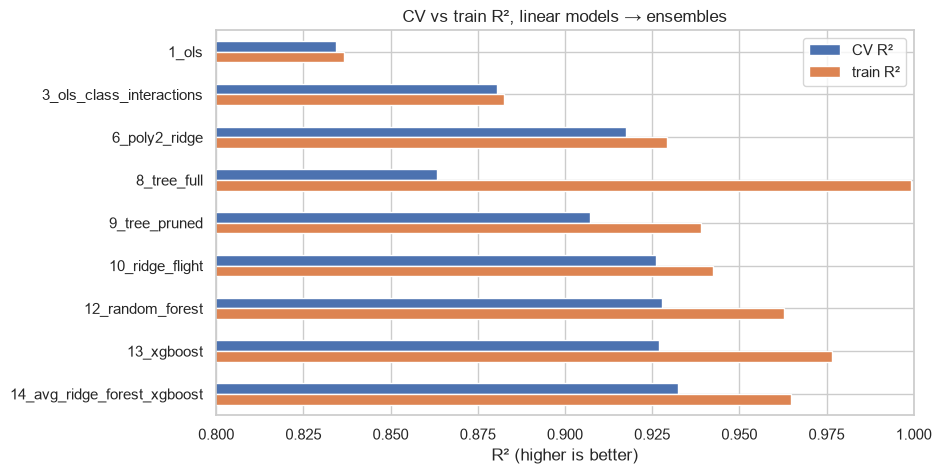

In [12]:
log = pd.read_csv(config.results_dir(TASK) / "experiments.csv")
table = (log[["model", "params", "r2_mean", "r2_std", "train_r2_mean", "rmse_mean", "public_lb"]]
         .sort_values("r2_mean", ascending=False).reset_index(drop=True))
display(table.round(4))

main = ["1_ols", "3_ols_class_interactions", "6_poly2_ridge", "8_tree_full", "9_tree_pruned", "10_ridge_flight",
        "12_random_forest", "13_xgboost", "14_avg_ridge_forest_xgboost"]
plot = table.set_index("model").loc[main, ["r2_mean", "train_r2_mean"]]
ax = plot.rename(columns={"r2_mean": "CV R²", "train_r2_mean": "train R²"}).plot.barh(figsize=(9, 5))
ax.set(xlim=(0.8, 1.0), xlabel="R² (higher is better)", ylabel="", title="CV vs train R², linear models → ensembles")
ax.invert_yaxis()
plt.savefig(FIG_DIR / "ensembles_r2.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations (Comparison)**

- **Final ranking (CV R²):**
  1. **3-model average 0.9325**
  2. Random Forest 0.9278
  3. XGBoost 0.9271
  4. Ridge + flight 0.9262
  5. pruned tree 0.9073
  6. OLS 0.835
  7. baseline 0.289
- **The whole project in one story:**
  - the linear models gained by adding interactions (class, then pairwise, then flight);
  - the tree models gained by controlling variance (pruning, then averaging into a forest) or bias (boosting);
  - the final gain came from combining the two families, which make different mistakes.
- **CV vs public:** CV R² is measured on our training data (held-out folds); Kaggle's public score uses its own test rows. So far public has read +0.023 to +0.027 above CV for the same model (Ridge + flight: CV 0.9262 → public 0.9492). On that pattern this model should score around **0.955 public**. The earlier leaderboard top was ≈ 0.96.

## Submission

**What this cell does:** Fits the three-model average on all training rows, predicts the test set and writes the submission file.

**Why:** Checks the CV gain against the public leaderboard.

In [13]:
final = VotingRegressor([(p, best_models[p]) for p in ["ridge", "forest", "xgboost"]])
path, sub = evaluate.make_submission(final, X, y, X_test, test_ids, sample_sub, TASK, "14_avg_ridge_forest_xgboost")
print("saved:", path.name)
print(sub["price"].describe().round(0).to_string())

saved: 2026-10-11_14_avg_ridge_forest_xgboost.csv
count      3898.0
mean      29694.0
std       38022.0
min        3462.0
25%        7479.0
50%       10210.0
75%       36677.0
max      229672.0


**Observations (Submission)**

- File: `submissions/regression/2026-10-11_14_avg_ridge_forest_xgboost.csv`.
- Minimum prediction ₹3,462, slightly below the ₹3,801 floor: Ridge is floored, but XGBoost's sum of trees can dip below it. That affects only a handful of cheap rows, so the impact on R² is negligible (Phase 4: the floor was worth +0.0008 in total).
- **Public score 0.96080** (previous best 0.94922, +0.0116). The public-vs-CV offset is +0.028 (CV 0.9325), in line with +0.023 to +0.027 for earlier submissions, so CV keeps ranking every submission in the same order as the public leaderboard.

## Viva notes — likely questions

**Q: Why are you allowed to use Random Forest / XGBoost?** The TA ruled (11 Oct) that models built on concepts taught before the deadline are allowed if we can explain them. Both are built from decision trees, which were taught.

**Q: What's the difference between bagging and boosting?**

| | Bagging (Random Forest) | Boosting (XGBoost) |
|---|---|---|
| Trees | deep, trained **in parallel**, independently | shallow, trained **in sequence**, each on the previous errors |
| Fixes | variance | bias |
| Combine by | plain average | sum of small steps (η × tree) |
| More trees | never overfits, just plateaus (our curve: flat after 100) | can overfit (our curve: train ↑, CV flat after 1,000) |

**Q: Why does a Random Forest use random feature subsets, not just bootstrap samples?** Averaging only cancels errors that differ between trees. Variance of the average is ρσ² + (1 − ρ)σ²/n. Bootstrap alone leaves trees highly correlated (they all split on class/duration first), so ρσ² stays large. Random subsets lower ρ. On our data: max_features 1.0 (bagging) 0.9249 vs 0.5 → 0.9278.

**Q: Why is it called *gradient* boosting?** For squared error, the residual (y − ŷ) is the negative gradient of the loss with respect to ŷ. Fitting each tree to the residuals is a gradient-descent step in function space. The learning rate η is the step size.

**Q: Why did you integer-code categories for trees but one-hot them for Ridge?** Ridge multiplies a feature by a weight, so an integer code would claim airline 4 = 2 × airline 2. A tree only compares against thresholds, so any category can be isolated with a few splits. The integer code also keeps 1,500 flight keys as 1 column instead of 1,500.

**Q: Why don't trees need scaling?** A split "duration ≤ 9.5" becomes "≤ 950" if duration is multiplied by 100. Same partition, same tree.

**Q: Why does averaging three models help when each scores ~0.927?** Their errors are only partly correlated (0.85–0.93). Ridge is smooth and extrapolates; trees are step functions. Where one overshoots, another often doesn't. The least-correlated pair gained most, as the formula predicts.

**Q: Isn't the large train-vs-CV gap of the forest (0.963 vs 0.928) overfitting?** Not in the harmful sense. It's normal for a forest (each tree saw most training rows), and CV, the score on unseen rows, is the best of any single model and the most stable across folds. Overfitting only matters if it costs CV score.

**Q: Why is your public score higher than your CV score?** They are measured on different rows. CV averages over our 5 held-out folds of training data; public uses part of Kaggle's test set. Every submission so far reads +0.023 to +0.027 higher on public, consistently, so CV still ranks models correctly.

**Q: Why not CatBoost?** We tried it: CV 0.922 and 6.5 minutes per CV run. Not better, and one more algorithm to defend.

**Q: Why equal weights in the average?** Tuning weights on the same CV folds would fit the folds' noise (the same optimistic bias as picking the best of many settings). Equal weights have nothing to tune.

## Summary

| | CV R² | Public |
|---|---|---|
| Phase 4: Ridge + flight × class | 0.9262 | 0.9492 |
| Random Forest (max_features 0.5, leaf ≥ 3) | 0.9278 | |
| XGBoost (depth 8, min_child_weight 20, 2,000 trees, η 0.02) | 0.9271 | |
| **Average of Ridge + RF + XGBoost** | **0.9325** | **0.9608** |

**What Phase 4b established**
1. On their own, the ensembles only tie Ridge (≈ 0.927): the remaining error is mostly the noise found in Phase 4, which no model can fit.
2. **Combining model families is what helps** (+0.006). The gain is ordered by how *un*correlated the models' errors are.
3. Our own data shows the bias–variance mechanics of both ensembles: forests improve with more trees and never get worse; boosting starts underfit and eventually overfits.